# 3. Autoencoders, Gradient Descent and GANs

Practice for module 3: gradient descent and the learning rate, numerical gradient checks for L2 and
BCE, an autoencoder that compresses 2D shapes through a bottleneck, and a 1D GAN with
alternating generator / discriminator updates.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
plt.rcParams["figure.dpi"] = 80
rng = np.random.default_rng(0)

## 3.1 Gradient descent: `w = w - lr * grad`

On `f(w) = (w - 3)^2` the gradient points uphill, so we subtract it. The learning rate is the step size:
too small is slow, too large overshoots and diverges.

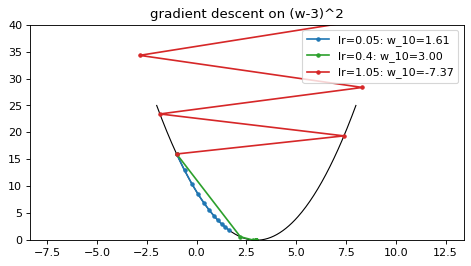

In [2]:
f = lambda w: (w - 3) ** 2
df = lambda w: 2 * (w - 3)

fig, ax = plt.subplots(figsize=(7, 3.5))
ws = np.linspace(-2, 8, 200); ax.plot(ws, f(ws), "k", lw=1)
for lr, c in [(0.05, "tab:blue"), (0.4, "tab:green"), (1.05, "tab:red")]:
    w, path = -1.0, [-1.0]
    for _ in range(10):
        w = w - lr * df(w); path.append(w)
    path = np.array(path)
    ax.plot(path, f(path), "o-", color=c, ms=3, label=f"lr={lr}: w_10={path[-1]:.2f}")
ax.set_ylim(0, 40); ax.legend(); ax.set_title("gradient descent on (w-3)^2")
plt.show()

## 3.2 Numerical gradient check: L2 and BCE

Nudge a parameter by ±ε, measure the change in loss, compare with the analytic gradient.
For BCE on a logit the analytic gradient is simply `prediction - target`.

In [3]:
def numeric_grad(loss, w, eps=1e-6):
    g = np.zeros_like(w)
    for i in range(w.size):
        e = np.zeros_like(w); e.flat[i] = eps
        g.flat[i] = (loss(w + e) - loss(w - e)) / (2 * eps)
    return g

X = rng.normal(size=(20, 3)); t = rng.normal(size=20); w0 = rng.normal(size=3)

l2 = lambda w: np.sum((X @ w - t) ** 2)
l2_grad = 2 * X.T @ (X @ w0 - t)
print("L2  max diff:", np.abs(numeric_grad(l2, w0) - l2_grad).max())

sigmoid = lambda z: 1 / (1 + np.exp(-z))
bce = lambda z, y: -(y * np.log(sigmoid(z)) + (1 - y) * np.log(1 - sigmoid(z)))
z0, y0 = np.array([0.7]), 1.0
print("BCE numeric:", numeric_grad(lambda z: bce(z, y0).sum(), z0), " prediction - target:", sigmoid(z0) - y0)

L2  max diff: 4.008175125136404e-09
BCE numeric: [-0.3318]  prediction - target: [-0.3318]


## 3.3 Autoencoder: 64-pixel images -> 2-number code -> 64-pixel images

Synthetic 8×8 images of a Gaussian blob at a random position. Only two numbers (x, y) really vary,
so a 2-unit bottleneck is enough. Encoder and decoder are 1-hidden-layer MLPs with tanh, trained by
backprop on L2 reconstruction error.

reconstruction L2: start 7.119 -> end 0.154


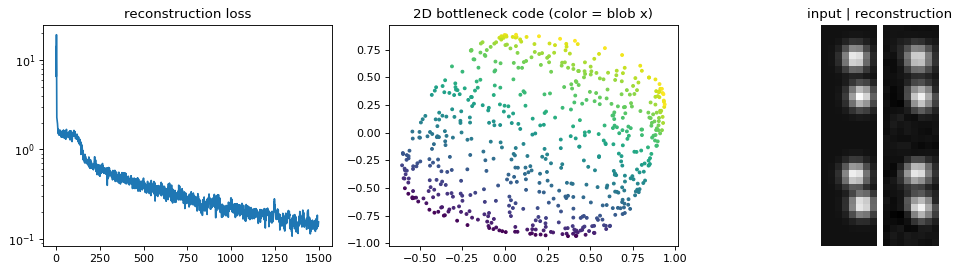

In [4]:
S = 8
gy, gx = np.mgrid[:S, :S]
def blob(cx, cy, s=1.2):
    return np.exp(-((gx - cx) ** 2 + (gy - cy) ** 2) / (2 * s ** 2)).ravel()

centers = rng.uniform(1.5, S - 2.5, size=(600, 2))
D = np.stack([blob(cx, cy) for cx, cy in centers])         # (600, 64)

def init(n_in, n_out): return rng.normal(0, 1 / np.sqrt(n_in), (n_in, n_out)), np.zeros(n_out)
sizes = [64, 32, 2, 32, 64]                                  # encoder | bottleneck | decoder
params = [init(a, b) for a, b in zip(sizes[:-1], sizes[1:])]

def forward(x):
    acts, h = [x], x
    for i, (W, b) in enumerate(params):
        h = h @ W + b
        if i < len(params) - 1: h = np.tanh(h)   # linear bottleneck output is fine too, tanh keeps it bounded
        acts.append(h)
    return acts

lr, losses = 0.05, []
for epoch in range(1500):
    batch = D[rng.choice(len(D), 64, replace=False)]
    acts = forward(batch)
    err = acts[-1] - batch
    losses.append(np.mean(np.sum(err ** 2, axis=1)))
    grad = 2 * err / len(batch)                   # gradient starts at the output layer...
    for i in reversed(range(len(params))):        # ...and flows back by the chain rule
        W, b = params[i]
        dW, db = acts[i].T @ grad, grad.sum(0)
        grad = grad @ W.T
        if i > 0: grad *= 1 - acts[i] ** 2         # tanh'
        params[i] = (W - lr * dW, b - lr * db)

acts = forward(D)
code, recon = acts[2], acts[-1]
print(f"reconstruction L2: start {losses[0]:.3f} -> end {losses[-1]:.3f}")

fig = plt.figure(figsize=(13, 3.5))
ax = fig.add_subplot(1, 3, 1); ax.plot(losses); ax.set_title("reconstruction loss"); ax.set_yscale("log")
ax = fig.add_subplot(1, 3, 2); ax.scatter(*code.T, c=centers[:, 0], cmap="viridis", s=6)
ax.set_title("2D bottleneck code (color = blob x)")
ax = fig.add_subplot(1, 3, 3); ax.axis("off")
pairs = np.vstack([np.hstack([D[i].reshape(S, S), np.ones((S, 1)), recon[i].reshape(S, S)]) for i in range(4)])
ax.imshow(pairs, cmap="gray"); ax.set_title("input | reconstruction")
plt.tight_layout(); plt.show()

## 3.4 Decoder as a generator: walk through the latent space

Feeding new codes into the decoder alone produces new images: the blob moves smoothly.

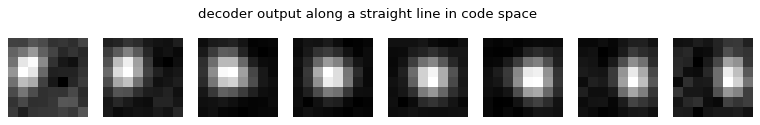

In [5]:
def decode(z):
    h = z
    for i, (W, b) in enumerate(params[2:]):
        h = h @ W + b
        if i < 1: h = np.tanh(h)
    return h

zs = np.linspace(code.min(0), code.max(0), 8)
fig, axes = plt.subplots(1, 8, figsize=(12, 1.8))
for a, z in zip(axes, zs):
    a.imshow(decode(z[None])[0].reshape(S, S), cmap="gray"); a.axis("off")
plt.suptitle("decoder output along a straight line in code space"); plt.show()

## 3.5 A 1D GAN

Real data: `N(4, 0.6)`. Generator: `G(z) = a·z + b` with `z ~ N(0, 1)` (noise -> data).
Discriminator: logistic regression on `[x, x²]`, which is enough to compare means and spreads.
Each step alternates one discriminator update and one generator update (non-saturating loss).
Balance matters: if G moves as fast as D, it collapses onto the real mean with zero spread (mode collapse).

generator: mean 4.01 (target 4.0), std 0.57 (target 0.6)


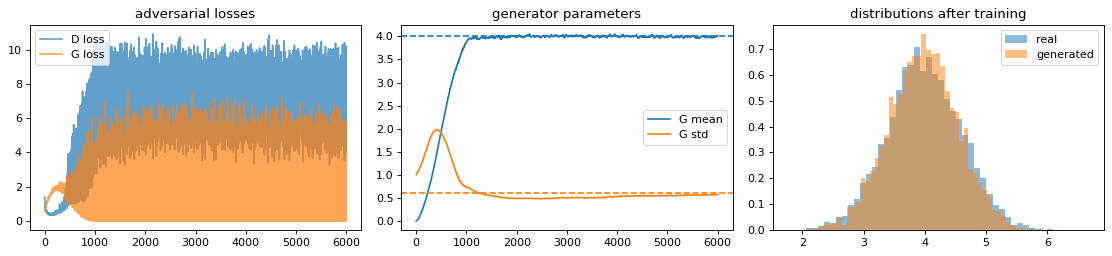

In [6]:
def D_logit(x, th):  return th[0] * x + th[1] * x ** 2 + th[2]

a, b = 1.0, 0.0                       # generator params
th = np.zeros(3)                      # discriminator params
lr_d, lr_g, n = 0.05, 0.01, 128      # D learns faster than G; with equal rates G collapses to a point
hist = {"d_loss": [], "g_loss": [], "mean": [], "std": []}

for step in range(6000):
    # --- discriminator step: real -> 1, fake -> 0 ---
    xr = rng.normal(4, 0.6, n); z = rng.normal(size=n); xf = a * z + b
    sr, sf = sigmoid(D_logit(xr, th)), sigmoid(D_logit(xf, th))
    d_loss = -np.mean(np.log(sr + 1e-9) + np.log(1 - sf + 1e-9))
    gr, gf = (sr - 1) / n, sf / n                        # BCE grad wrt logit = prediction - target
    th -= lr_d * np.array([gr @ xr + gf @ xf, gr @ xr ** 2 + gf @ xf ** 2, gr.sum() + gf.sum()])

    # --- generator step: make D call fakes real ---
    z = rng.normal(size=n); xf = a * z + b
    sf = sigmoid(D_logit(xf, th))
    g_loss = -np.mean(np.log(sf + 1e-9))
    dx = (sf - 1) / n * (th[0] + 2 * th[1] * xf)         # chain rule through D into the sample
    a -= lr_g * (dx @ z); b -= lr_g * dx.sum()

    hist["d_loss"].append(d_loss); hist["g_loss"].append(g_loss)
    hist["mean"].append(b); hist["std"].append(abs(a))

print(f"generator: mean {b:.2f} (target 4.0), std {abs(a):.2f} (target 0.6)")

fig, axes = plt.subplots(1, 3, figsize=(14, 3.3))
axes[0].plot(hist["d_loss"], label="D loss", alpha=0.7); axes[0].plot(hist["g_loss"], label="G loss", alpha=0.7)
axes[0].legend(); axes[0].set_title("adversarial losses")
axes[1].plot(hist["mean"], label="G mean"); axes[1].plot(hist["std"], label="G std")
axes[1].axhline(4, ls="--", c="C0"); axes[1].axhline(0.6, ls="--", c="C1"); axes[1].legend()
axes[1].set_title("generator parameters")
axes[2].hist(rng.normal(4, 0.6, 5000), bins=50, density=True, alpha=0.5, label="real")
axes[2].hist(a * rng.normal(size=5000) + b, bins=50, density=True, alpha=0.5, label="generated")
axes[2].legend(); axes[2].set_title("distributions after training")
plt.tight_layout(); plt.show()